<a href="https://colab.research.google.com/github/a00377571/lsm-reconocimiento-mediapipe/blob/main/An%C3%A1lisis_exploratorio_EDA_E47.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Maestría en Inteligencia Artificial Aplicada**.

**Curso: TC5035.10 - Proyecto Integrador**

Tecnológico de Monterrey

Profesor: Dr. Raúl Valente Ramírez Velarde

**Semana 2, Actividad 1**

Análisis Exploratorio de datos

---

*   **Estudiante:** Marco Antonio Arellano Hernández - A00377571
*   **Estudiante:** Miguel Octavio Ramírez Romero - A00828311
*   **Estudiante:** Hugo Enrique Navarro Villeda - A01796287

# **Parte 1: EDA y preprocesamiento**

**Importar módulos requeridos**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import os

In [3]:
# Cargar archivo CSV

df = pd.read_csv("dataset_base.csv")

print("Lectura de archivo CSV que contiene el dataset:")
print(df.head())

Lectura de archivo CSV que contiene el dataset:
   video_id  frame_id  timestamp   label  left_detectada  right_x0  right_y0  \
0         0         0        0.0  Word-A               0  0.286312  0.566639   
1         0         0        0.0  Word-A               0  0.269283  0.517021   
2         0         0        0.0  Word-A               1       NaN       NaN   
3         0         0        0.0  Word_-               0  0.238336  0.622394   
4         0         0        0.0  Word_A               0  0.374317  0.441127   

       right_z0  right_x1  right_y1  ...  left_angle_pinky_mcp  \
0 -2.310001e-07  0.324800  0.547244  ...                   NaN   
1 -2.148822e-07  0.296912  0.500848  ...                   NaN   
2           NaN       NaN       NaN  ...            161.650404   
3 -2.309069e-07  0.312799  0.584109  ...                   NaN   
4 -1.248119e-07  0.393573  0.431170  ...                   NaN   

   left_angle_between_index_middle  left_angle_between_middle_ring  \
0   

In [5]:
# Informacion básico del dataset
print("-"*50)
print("Informacion basica sobre el dataset:")
print("-"*50)
df.info()

print("-"*50)
print("Tipos de las columnas del dataset")
print("-"*50)
df.dtypes

--------------------------------------------------
Informacion basica sobre el dataset:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539 entries, 0 to 538
Columns: 227 entries, video_id to left_wrist_z
dtypes: float64(219), int64(7), object(1)
memory usage: 956.0+ KB
--------------------------------------------------
Tipos de las columnas del dataset
--------------------------------------------------


,0
video_id,int64
frame_id,int64
timestamp,float64
label,object
left_detectada,int64
...,...
left_hand_ori_x,float64
left_hand_ori_y,float64
left_wrist_x,float64
left_wrist_y,float64


In [6]:
numerical_columns = df.select_dtypes(include = ['int', 'float']).columns
categorical_columns = df.select_dtypes(include = ['object','category']).columns

print("Columnas por categoria")
print("Columnas numericas: ", numerical_columns.to_list())
print("Columnas categoricas: ", categorical_columns.to_list())
print(f"Numero de columnas numericas: {len(numerical_columns)}")
print(f"Numbero de columnas categoricas: {len(categorical_columns)}")

Columnas por categoria
Columnas numericas:  ['video_id', 'frame_id', 'timestamp', 'left_detectada', 'right_x0', 'right_y0', 'right_z0', 'right_x1', 'right_y1', 'right_z1', 'right_x2', 'right_y2', 'right_z2', 'right_x3', 'right_y3', 'right_z3', 'right_x4', 'right_y4', 'right_z4', 'right_x5', 'right_y5', 'right_z5', 'right_x6', 'right_y6', 'right_z6', 'right_x7', 'right_y7', 'right_z7', 'right_x8', 'right_y8', 'right_z8', 'right_x9', 'right_y9', 'right_z9', 'right_x10', 'right_y10', 'right_z10', 'right_x11', 'right_y11', 'right_z11', 'right_x12', 'right_y12', 'right_z12', 'right_x13', 'right_y13', 'right_z13', 'right_x14', 'right_y14', 'right_z14', 'right_x15', 'right_y15', 'right_z15', 'right_x16', 'right_y16', 'right_z16', 'right_x17', 'right_y17', 'right_z17', 'right_x18', 'right_y18', 'right_z18', 'right_x19', 'right_y19', 'right_z19', 'right_x20', 'right_y20', 'right_z20', 'right_dist_1', 'right_dist_2', 'right_dist_3', 'right_dist_4', 'right_dist_5', 'right_dist_6', 'right_dist_7',

In [7]:
# Muestreo de estadisticas generales de las columnas numericas
df[numerical_columns].describe()

,video_id,frame_id,timestamp,left_detectada,right_x0,right_y0,right_z0,right_x1,right_y1,right_z1,...,left_angle_pinky_mcp,left_angle_between_index_middle,left_angle_between_middle_ring,left_angle_between_ring_pinky,left_angle_between_index_pinky,left_hand_ori_x,left_hand_ori_y,left_wrist_x,left_wrist_y,left_wrist_z
count,539.0,539.0,539.0,539.000000,304.000000,304.000000,3.040000e+02,304.000000,304.000000,304.000000,...,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,2.400000e+02
mean,0.0,0.0,0.0,0.445269,0.267727,0.615666,1.592455e-07,0.310753,0.589819,-0.013712,...,127.107760,13.937812,14.439000,15.861176,43.514092,-0.043032,-0.125194,0.731429,0.691916,-2.768765e-07
std,0.0,0.0,0.0,0.497457,0.096520,0.162838,3.493077e-07,0.089773,0.148416,0.017285,...,34.403552,6.607304,5.384300,6.517487,15.258479,0.084552,0.109649,0.180660,0.164337,4.707612e-07
min,0.0,0.0,0.0,0.000000,0.057537,0.185685,-7.324654e-07,0.089266,0.203686,-0.097146,...,33.697693,4.389582,3.953052,3.757996,11.261378,-0.425323,-0.369252,0.038829,0.219118,-1.967007e-06
25%,0.0,0.0,0.0,0.000000,0.196828,0.498072,-4.018396e-08,0.244081,0.480026,-0.020339,...,102.994874,9.892710,10.451861,11.301413,32.645342,-0.082716,-0.205750,0.674810,0.586973,-6.279654e-07
50%,0.0,0.0,0.0,0.000000,0.267299,0.606028,1.072643e-07,0.312436,0.575302,-0.011355,...,134.352031,13.434104,14.014408,16.303105,42.914251,-0.033278,-0.148656,0.768497,0.714751,-2.419941e-07
75%,0.0,0.0,0.0,1.000000,0.334270,0.723876,3.270127e-07,0.374596,0.690214,-0.004956,...,155.535474,16.433451,17.830795,20.102930,52.963625,0.002780,-0.061052,0.840823,0.817525,9.915176e-08
max,0.0,0.0,0.0,1.000000,0.602477,1.051780,2.004499e-06,0.672690,0.998765,0.069328,...,173.359093,74.925073,32.056649,42.859958,109.204757,0.287883,0.179421,1.058479,0.996318,1.291141e-06


In [8]:
# Muestreo de estadisticas generales de la columna categorica
df[categorical_columns].describe()

,label
count,539
unique,28
top,Word_N
freq,34


In [20]:
df[categorical_columns].apply(lambda x: x.unique()).T

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
label,Word-A,Word_-,Word_A,Word_B,Word_C,Word_D,Word_E,Word_F,Word_G,Word_H,...,Word_Q,Word_R,Word_S,Word_T,Word_U,Word_V,Word_W,Word_X,Word_Z,Word_y


# **Descripción general del dataset**

Este dataset contiene datos de landmarks (puntos clave) de manos detectadas en video, con el objetivo de clasificar señas o palabras de un lenguaje de señas LSM. Para fines de esta práctica, se utilizaron imágenes fijas.


*   **Dimensiones:** 539 filas x 228 columnas
*   **Tamaño:** dataset mediano
*   **Formato:** cada fila representa un frame de un video con la informacion de las manos detectadas

**Variable objetivo: label**

Contiene la etiqueta de la seña/palabra que se está realizando. Los valores observados son:
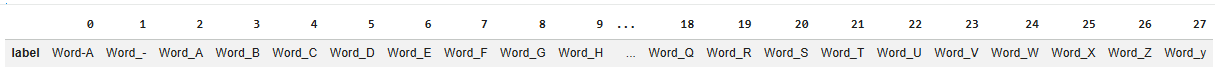


**Estructura de las columnas**

Columnas de identificación y metadatos

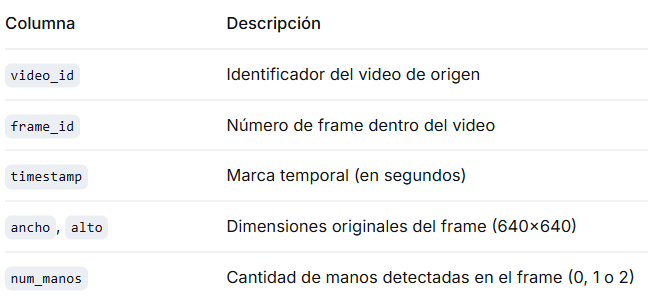

**Columnas de detección**

Existen dos columnas en este apartado: left_detectada y right_detectada, si aparece 1 es que se detectó la mano, 0 si no.

Landmarks por mano (21 puntos x 3 coordenadas por mano)

Para cada mano (left y right) hay:
{mano}_x0..x20, {mano}_y0..y20, {mano}_z0..z20: coordenadas normalizadas (0-1) de los 21 puntos clave de MediaPipe.

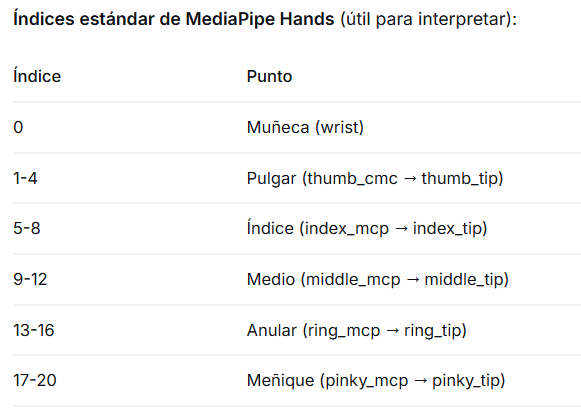


**Features multi-mano**


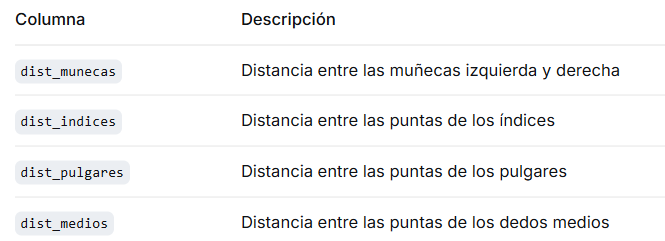

Estos capturan interacción entre las dos manos, podría ser clave para señas bimanuales.


**Particularidades importantes**

* **Muchos valores nulos (NaN):** Cuando no se detecta una mano, todas sus columnas quedan vacías
* **Datos repetidos por frame:** Un mismo video aporta muchas filas lo que genera un desbalance temporal; por otro lado, una fuga de datos si se divide aleotariamente y no se toma en cuenta dividir por video_id y no por fila.
* **Coordenadas normalizadas:** Las coordenadas x,y están en [0,1] respecto al frame

